<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson2/Lesson2_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Math for Neuroscience & Machine Learning**
## Lesson 2 — Dot Products, Neural Similarity, Weighted Inputs, and Projection

**Course:** Math for Neuroscience & Machine Learning\
**Lesson:** Lesson 2\
**Notebook type:** Teaching notebook

> *"A dot product tells us whether two neural activity patterns point the same way, how
> strongly a neuron responds to what it is given, and how much of a signal lies along a
> direction we care about."*

---

### Import Dependencies

In [1]:
# SETUP CELL -- run this once before anything else in the notebook.
import numpy as np
import matplotlib.pyplot as plt
RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers used in Lesson 1.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

In [2]:
# INTERACTIVE/ANIMATION SETUP -- run after the setup cell above.
from pathlib import Path

import plotly.graph_objects as go
from plotly.subplots import make_subplots

from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML, Video, display

PLOTLY_MARKERS = ['circle', 'square', 'triangle-up', 'diamond', 'triangle-down', 'cross']

# Same base configuration as Lesson 1.
PLOTLY_CONFIG = {
    'displaylogo': False,
    'responsive': True,
    'scrollZoom': True,
    'toImageButtonOptions': {
        'format': 'png',
        'scale': 2,
    },
}

ANIMATION_FPS = 20
ANIMATION_DPI = 140
ANIMATION_OUTPUT_DIR = Path('lesson2_animations')
ANIMATION_OUTPUT_DIR.mkdir(exist_ok=True)


def padded_limits(values, fraction=0.12, minimum_padding=0.5):
    # Return stable axis limits with a small padding around the data.
    values = np.asarray(values, dtype=float)
    lo = float(np.nanmin(values))
    hi = float(np.nanmax(values))
    span = hi - lo
    pad = minimum_padding if span == 0 else fraction * span
    return lo - pad, hi + pad


def no_grid(ax_or_axes):
    # LESSON 2 STANDARD: every static Matplotlib axis explicitly disables its grid.
    axes = np.atleast_1d(ax_or_axes).ravel()
    for ax in axes:
        ax.grid(False)


def style_plotly_axes(fig, **kwargs):
    # LESSON 2 STANDARD: every Cartesian Plotly axis explicitly disables its gridlines.
    fig.update_xaxes(showgrid=False, zeroline=False, **kwargs)
    fig.update_yaxes(showgrid=False, zeroline=False, **kwargs)
    return fig


def display_matplotlib_animation(animation, fps=ANIMATION_FPS):
    # Show a Matplotlib animation with browser play/pause controls (no FFmpeg required).
    display(HTML(animation.to_jshtml(fps=fps, default_mode='once')))


def play_pause_buttons(x=0.03, y=-0.12):
    # A reusable Plotly Play/Pause button pair, styled like Lesson 1's.
    return dict(
        type='buttons', showactive=False, x=x, y=y, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate',
                 args=[None, {'frame': {'duration': 60, 'redraw': True},
                              'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate',
                 args=[[None], {'frame': {'duration': 0, 'redraw': False},
                                 'mode': 'immediate'}]),
        ],
    )


def frame_slider(labels, prefix=''):
    # A reusable Plotly frame slider matching Lesson 1's animation pattern.
    return dict(
        active=0,
        currentvalue={'prefix': prefix},
        pad={'t': 40},
        steps=[
            dict(label=str(lab), method='animate',
                 args=[[str(k)], {'mode': 'immediate',
                                   'frame': {'duration': 0, 'redraw': True},
                                   'transition': {'duration': 0}}])
            for k, lab in enumerate(labels)
        ],
    )


print('Interactive plotting and animation tools are ready.')
print('Any saved animation assets would be written to:', ANIMATION_OUTPUT_DIR.resolve())

Interactive plotting and animation tools are ready.
Any saved animation assets would be written to: /content/lesson2_animations


# **Concept map**

Dot product → (as a sum) weighted input, ML score → (as geometry) angle, cosine similarity
→ (as decomposition) projection, residual → (feeding forward) matrices as collections of
vectors, regression, PCA, and neural decoding.

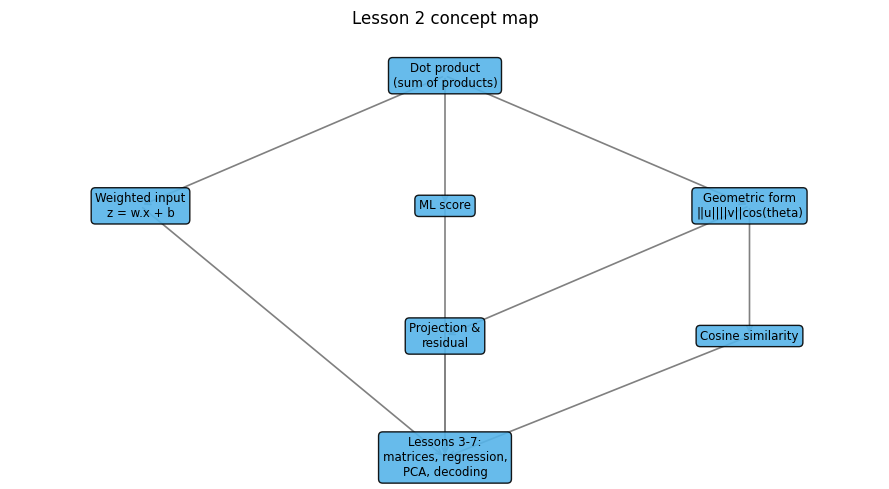

In [3]:
# A compact visual concept map.
fig, ax = plt.subplots(figsize=(9, 5))
ax.axis('off')

nodes = {
    'Dot product\n(sum of products)': (0.5, 0.9),
    'Weighted input\nz = w.x + b': (0.15, 0.6),
    'ML score': (0.5, 0.6),
    'Geometric form\n||u||||v||cos(theta)': (0.85, 0.6),
    'Cosine similarity': (0.85, 0.3),
    'Projection &\nresidual': (0.5, 0.3),
    'Lessons 3-7:\nmatrices, regression,\nPCA, decoding': (0.5, 0.02),
}
edges = [
    ('Dot product\n(sum of products)', 'Weighted input\nz = w.x + b'),
    ('Dot product\n(sum of products)', 'ML score'),
    ('Dot product\n(sum of products)', 'Geometric form\n||u||||v||cos(theta)'),
    ('Geometric form\n||u||||v||cos(theta)', 'Cosine similarity'),
    ('Geometric form\n||u||||v||cos(theta)', 'Projection &\nresidual'),
    ('Weighted input\nz = w.x + b', 'Lessons 3-7:\nmatrices, regression,\nPCA, decoding'),
    ('ML score', 'Lessons 3-7:\nmatrices, regression,\nPCA, decoding'),
    ('Cosine similarity', 'Lessons 3-7:\nmatrices, regression,\nPCA, decoding'),
    ('Projection &\nresidual', 'Lessons 3-7:\nmatrices, regression,\nPCA, decoding'),
]
for a, b in edges:
    xa, ya = nodes[a]; xb, yb = nodes[b]
    ax.annotate('', xy=(xb, yb), xytext=(xa, ya),
                arrowprops=dict(arrowstyle='->', color='grey', lw=1.2))
for label, (x, y) in nodes.items():
    ax.text(x, y, label, ha='center', va='center', fontsize=8.5,
            bbox=dict(boxstyle='round,pad=0.35', facecolor=PALETTE[5], edgecolor='black', alpha=0.9))
ax.set_title('Lesson 2 concept map')
no_grid(ax)
plt.tight_layout()
plt.show()

# **Part 1: Dot product as a sum of products**

Suppose a simplified neuron receives $n$ inputs. Input $i$ arrives with strength $x_i$
(think of it as a firing rate or an input current), and the connection carrying that input
has weight $w_i$. The **total
weighted input** the neuron receives is:

$$
z = \mathbf{w} \cdot \mathbf{x} = \sum_{i=1}^{n} w_i x_i = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n.
$$

This is the **dot product** (also called the inner product): multiply each pair of
corresponding coordinates, then add up the products. Two conditions must hold:

- $\mathbf{w}$ and $\mathbf{x}$ must have the **same number of coordinates** ($n$) —
  otherwise there is nothing to pair up.
- Coordinate $i$ of $\mathbf{w}$ must refer to the **same input line** as coordinate $i$
  of $\mathbf{x}$.

**Units.** If $x_i$ is measured in spikes/s and $w_i$ is dimensionless, each term $w_i x_i$
is in spikes/s, and so is the sum $z$.

**The same equation drives artificial neurons too.** In machine learning, $z = \mathbf{w}\cdot\mathbf{x} + b$ (with a bias term $b$) is exactly the *pre-activation* of a single artificial neuron or a linear layer: $\mathbf{x}$ holds the inputs (pixel intensities, word counts, or the outputs of an earlier layer), $\mathbf{w}$ holds the learned connection strengths, and $z$ is passed on (often through a nonlinearity) to the next stage.

![Single artificial neuron](https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/main/lesson2/images/single_an.png)

In [4]:
# A simplified neuron with four inputs.
x_inputs = np.array([2.0, 3.0, 1.0, 4.0])     # input strengths (arbitrary units)
w_weights = np.array([0.8, -0.5, 0.3, 0.0])   # connection weights (dimensionless here)

print("Inputs  x:", x_inputs)
print("Weights w:", w_weights)
print("Same length?", x_inputs.shape == w_weights.shape)

Inputs  x: [2. 3. 1. 4.]
Weights w: [ 0.8 -0.5  0.3  0. ]
Same length? True


### Manual calculation, a loop, and NumPy

The same number, computed three ways: by hand, with an explicit Python loop, and with
NumPy.

In [5]:
# Manual calculation (writing out every term)
manual = (w_weights[0] * x_inputs[0] + w_weights[1] * x_inputs[1]
          + w_weights[2] * x_inputs[2] + w_weights[3] * x_inputs[3])
print("Manual sum of products:", manual)

# Explicit Python loop -- the general-n version of the manual calculation above
def dot_loop(a, b):
    if a.shape != b.shape:
        raise ValueError(f"Shape mismatch: {a.shape} vs {b.shape}")
    total = 0.0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

loop_result = dot_loop(w_weights, x_inputs)
print("Loop result:          ", loop_result)

# NumPy -- np.dot and the @ operator are equivalent for 1-D arrays
numpy_dot = np.dot(w_weights, x_inputs)

numpy_at = w_weights @ x_inputs
print("np.dot result:        ", numpy_dot)
print("w @ x result:         ", numpy_at)

print("\nAll four agree?", np.isclose(manual, loop_result)
      and np.isclose(loop_result, numpy_dot) and np.isclose(numpy_dot, numpy_at))

Manual sum of products: 0.4000000000000001
Loop result:           0.4000000000000001
np.dot result:         0.4000000000000001
w @ x result:          0.4000000000000001

All four agree? True


**A shape caution.** `np.dot` and `@` will raise an error for mismatched 1-D lengths, which
is helpful — but they can also silently broadcast or misbehave for arrays that are not
plain 1-D vectors (e.g. a `(4,)` array against a `(4, 1)` column). Before computing a dot
product, check `.shape` on both arrays, exactly as you learned to do in Lesson 1.

In [6]:
# A shape mismatch is caught immediately and clearly.
short_vector = np.array([1.0, 2.0, 3.0])
try:
    np.dot(w_weights, short_vector)
except ValueError as err:
    print("Caught the expected error:", err)

Caught the expected error: shapes (4,) and (3,) not aligned: 4 (dim 0) != 3 (dim 0)


### Interactive coordinate-contribution view

Each bar below is one term $w_i x_i$ in the sum. Hover over a bar to see the input, the
weight, and that coordinate's individual contribution to the total. The dashed line marks
the total weighted input $z = \mathbf{w} \cdot \mathbf{x}$.

**Try:** compare the height of each bar with its sign. A negative weight paired with a
positive input produces a negative contribution, which *reduces* the total even though the
input itself was positive.

In [7]:
# Coordinate-contribution bar chart
contributions = w_weights * x_inputs
labels = [f"input {i+1}" for i in range(len(x_inputs))]
bar_colors = [PALETTE[0] if c >= 0 else PALETTE[1] for c in contributions]

fig_interactive = go.Figure()
fig_interactive.add_trace(go.Bar(
    x=labels, y=contributions,
    marker_color=bar_colors, marker_line_color='black', marker_line_width=0.8,
    customdata=np.stack([w_weights, x_inputs], axis=1),
    hovertemplate=('%{x}<br>weight w_i = %{customdata[0]:.2f}<br>'
                   'input x_i = %{customdata[1]:.2f}<br>'
                   'contribution w_i x_i = %{y:.2f}<extra></extra>'),
    name='contribution',
))
fig_interactive.add_hline(y=contributions.sum(), line_dash='dash', line_color=PALETTE[2],
                           annotation_text=f'total z = {contributions.sum():.2f}',
                           annotation_position='top right')
fig_interactive.add_hline(y=0, line_width=1, line_color='grey')
fig_interactive.update_layout(
    title='Coordinate-wise contributions to the dot product (hover for detail)',
    yaxis_title='Contribution  w_i x_i',
    template='plotly_white', width=680, height=440,
)
style_plotly_axes(fig_interactive)
fig_interactive.show(config=PLOTLY_CONFIG)

# **Part 2: Dot-product properties**

Let $\mathbf{u}, \mathbf{v}, \mathbf{w}$ be vectors of the same length and $c$ a
scalar.

| Property | Statement | Why it matters here |
|---|---|---|
| Commutativity | $\mathbf{u}\cdot\mathbf{v}$ $= \mathbf{v}\cdot\mathbf{u}$ | Comparing pattern A to B gives the same number as comparing B to A. |
| Distributivity | $\mathbf{u}\cdot(\mathbf{v}$ $+\mathbf{w})$ $= \mathbf{u}\cdot\mathbf{v}$ $+ \mathbf{u}\cdot\mathbf{w}$ | Combining two input sources adds their weighted contributions. |
| Scalar linearity | $\mathbf{u}\cdot(c\,\mathbf{v})$ $=$ $c\,(\mathbf{u}\cdot\mathbf{v})$ | Rescaling an input rescales its weighted contribution by the same factor. |
| Self dot product | $\mathbf{v}\cdot\mathbf{v}$ $= \lVert \mathbf{v} $ $\rVert^2 \ge 0$ | The dot product of a vector with itself is never negative, and recovers the squared norm from Lesson 1. |

We will not prove these formally; instead we verify them numerically.

In [8]:
# Numerical verification of the four properties above.
u_vec = np.array([2.0, -1.0, 3.0])
v_vec = np.array([0.5, 4.0, -2.0])
w_vec = np.array([1.0, 1.0, 1.0])
c_scalar = 3.0

commutative_ok    = np.isclose(u_vec @ v_vec, v_vec @ u_vec)
distributive_ok   = np.isclose(u_vec @ (v_vec + w_vec), u_vec @ v_vec + u_vec @ w_vec)
scalar_linear_ok  = np.isclose(u_vec @ (c_scalar * v_vec), c_scalar * (u_vec @ v_vec))
self_dot_ok       = np.isclose(v_vec @ v_vec, np.linalg.norm(v_vec) ** 2)

print("Commutativity   u.v == v.u              :", commutative_ok)
print("Distributivity  u.(v + w) == u.v + u.w  :", distributive_ok)
print("Scalar linearity u.(cv) == c(u.v)       :", scalar_linear_ok)
print("Self dot product v.v == ||v||^2         :", self_dot_ok)

Commutativity   u.v == v.u              : True
Distributivity  u.(v + w) == u.v + u.w  : True
Scalar linearity u.(cv) == c(u.v)       : True
Self dot product v.v == ||v||^2         : True


# **Part 3: The geometric interpretation**

The dot product has a second, equivalent formula that involves geometry directly:

$$
\mathbf{u}\cdot\mathbf{v} = \lVert \mathbf{u} \rVert \, \lVert \mathbf{v} \rVert \cos\theta,
$$

where $\theta$ is the angle between $\mathbf{u}$ and $\mathbf{v}$. This is exactly the same
number as the coordinate-wise sum from Part 1 — it is a different formula for the same
quantity.

Rearranging gives us a way to compute the angle between two vectors:

$$
\theta = \arccos\!\left(\frac{\mathbf{u}\cdot\mathbf{v}}{\lVert \mathbf{u}\rVert\,\lVert \mathbf{v}\rVert}\right).
$$

**A numerical safeguard:** Floating-point rounding can occasionally push the ratio above
$1.0$ or below $-1.0$ by a tiny amount (e.g. `1.0000000002`), and `arccos` of such a value
returns `nan`. Always clip the ratio into $[-1, 1]$ first with `np.clip`.

The **sign** of the dot product tells you which of three regimes you are in:

- $\mathbf{u}\cdot\mathbf{v} > 0$: the angle is acute ($\theta < 90^\circ$) — the vectors
  point in broadly the same direction.
- $\mathbf{u}\cdot\mathbf{v} = 0$: the angle is exactly $90^\circ$ — the vectors are
  **orthogonal**.
- $\mathbf{u}\cdot\mathbf{v} < 0$: the angle is obtuse ($\theta > 90^\circ$) — the vectors
  point in broadly opposite directions.

In [9]:
def angle_between(a, b, eps=1e-12):
    # Angle in degrees between two nonzero vectors, with a safe arccos clip.
    norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
    if norm_a < eps or norm_b < eps:
        raise ValueError("angle_between is undefined for a zero vector.")
    cos_theta = np.clip((a @ b) / (norm_a * norm_b), -1.0, 1.0)
    return np.degrees(np.arccos(cos_theta))

u_demo = np.array([1.0, 0.0])
v_demo = np.array([1.0, 1.0])
print(f"Angle between {u_demo} and {v_demo}: {angle_between(u_demo, v_demo):.2f} degrees")
print(f"Dot product:  {u_demo @ v_demo:.3f}  (positive -> acute angle)")

# The near-boundary case that motivates clipping.
almost_parallel = np.array([1.0, 1e-9])
cos_raw = (u_demo @ almost_parallel) / (np.linalg.norm(u_demo) * np.linalg.norm(almost_parallel))
print(f"\nRaw cosine before clipping: {cos_raw!r}")
print("Clipped to [-1, 1]:", np.clip(cos_raw, -1.0, 1.0))

Angle between [1. 0.] and [1. 1.]: 45.00 degrees
Dot product:  1.000  (positive -> acute angle)

Raw cosine before clipping: np.float64(1.0)
Clipped to [-1, 1]: 1.0


### Static reference figure: three vector pairs, three signs

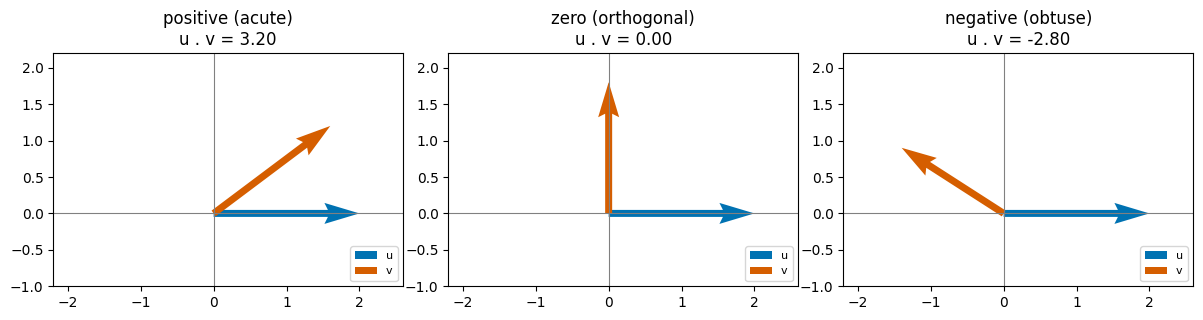

In [10]:
# Static figure: positive, zero, and negative dot product cases.
fixed_vec = np.array([2.0, 0.0])
case_vectors = {
    'positive (acute)': np.array([1.6, 1.2]),
    'zero (orthogonal)': np.array([0.0, 1.8]),
    'negative (obtuse)': np.array([-1.4, 0.9]),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (label, v) in zip(axes, case_vectors.items()):
    dp = fixed_vec @ v
    ax.quiver(0, 0, fixed_vec[0], fixed_vec[1], angles='xy', scale_units='xy', scale=1,
              color=PALETTE[0], width=0.02, label='u')
    ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1,
              color=PALETTE[1], width=0.02, label='v')
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    ax.set_xlim(-2.2, 2.6); ax.set_ylim(-1.0, 2.2)
    ax.set_aspect('equal')
    ax.set_title(f"{label}\nu . v = {dp:.2f}")
    ax.legend(loc='lower right', fontsize=8)
no_grid(axes)
plt.tight_layout()
plt.show()

### Interactive rotation animation: angle, cosine, and dot product together

Rotate $\mathbf{v}$ through a full turn while $\mathbf{u}$ stays fixed. Press **Play** or
drag the angle slider. Watch the angle, cosine, and dot product update together, and note
the two moments the dot product crosses zero.

In [11]:
# INTERACTIVE ANIMATION -- rotating v, with live angle / cosine / dot-product readout.
u_fixed = np.array([2.0, 0.0])
angles_deg = np.arange(0, 361, 4)
angles_rad = np.radians(angles_deg)
v_len = 1.8
v_rot = np.stack([v_len * np.cos(angles_rad), v_len * np.sin(angles_rad)], axis=1)
dot_values = v_rot @ u_fixed
cos_values = dot_values / (np.linalg.norm(u_fixed) * v_len)

axis_lim = 2.4

def rotation_frame_data(k):
    # Only the two traces actually reused below (u fixed, v rotating) are built here;
    # the current-angle marker on the right-hand panel is created separately.
    v = v_rot[k]
    return [
        go.Scatter(x=[0, u_fixed[0]], y=[0, u_fixed[1]], mode='lines+markers',
                   line=dict(color=PALETTE[0], width=5),
                   marker=dict(size=[1, 12], symbol=['circle', 'triangle-right']),
                   name='u (fixed)'),
        go.Scatter(x=[0, v[0]], y=[0, v[1]], mode='lines+markers',
                   line=dict(color=PALETTE[1], width=5),
                   marker=dict(size=[1, 12], symbol=['circle', 'triangle-right']),
                   name='v (rotating)'),
    ]

fig_rotation = make_subplots(
    rows=1, cols=2,
    subplot_titles=('u fixed, v rotating', 'dot product vs. angle'),
    column_widths=[0.42, 0.58],
)
init_traces = rotation_frame_data(0)
fig_rotation.add_trace(init_traces[0], row=1, col=1)
fig_rotation.add_trace(init_traces[1], row=1, col=1)
fig_rotation.add_trace(go.Scatter(x=angles_deg, y=dot_values, mode='lines',
                                   line=dict(color='lightgrey', width=2),
                                   name='u . v (full curve)', hoverinfo='skip'), row=1, col=2)
fig_rotation.add_trace(go.Scatter(x=[angles_deg[0]], y=[dot_values[0]], mode='markers',
                                   marker=dict(color=PALETTE[2], size=11),
                                   name='current angle'), row=1, col=2)
fig_rotation.add_hline(y=0, line_width=1, line_color='grey', row=1, col=2)
for marker_angle in (90, 270):
    fig_rotation.add_vline(x=marker_angle, line_dash='dot', line_color=PALETTE[3], row=1, col=2)

frames = []
for k in range(len(angles_deg)):
    v = v_rot[k]
    frames.append(go.Frame(
        name=str(k),
        data=[
            go.Scatter(x=[0, v[0]], y=[0, v[1]]),
            go.Scatter(x=[angles_deg[k]], y=[dot_values[k]]),
        ],
        traces=[1, 3],
    ))
fig_rotation.frames = frames

fig_rotation.update_xaxes(range=[-axis_lim, axis_lim], title_text='coordinate 1', row=1, col=1,
                           scaleanchor='y', scaleratio=1)
fig_rotation.update_yaxes(range=[-axis_lim, axis_lim], title_text='coordinate 2', row=1, col=1)
fig_rotation.update_xaxes(range=[0, 360], title_text='angle theta (degrees)', row=1, col=2)
fig_rotation.update_yaxes(range=list(padded_limits(dot_values)), title_text='u . v', row=1, col=2)
style_plotly_axes(fig_rotation)

fig_rotation.update_layout(
    title='Rotating v: live angle, cosine, and dot product (Play, or drag the slider)',
    template='plotly_white', width=980, height=460,
    updatemenus=[play_pause_buttons(x=0.0, y=-0.18)],
    sliders=[frame_slider([f'{a} deg' for a in angles_deg], prefix='angle = ')],
)
fig_rotation.show(config=PLOTLY_CONFIG)

print("Press Play or drag the angle slider.")
print("Orthogonality markers (dotted vertical lines) sit at 90 and 270 degrees, where u.v = 0.")

Press Play or drag the angle slider.
Orthogonality markers (dotted vertical lines) sit at 90 and 270 degrees, where u.v = 0.


**Interpretation.** As $\mathbf{v}$ sweeps through $360^\circ$, the dot product traces a
cosine-shaped curve: maximal when $\mathbf{v}$ points the same way as $\mathbf{u}$ ($\theta
= 0^\circ$), zero at $90^\circ$ and $270^\circ$, and most negative when the two vectors
point directly opposite ($\theta = 180^\circ$). The dot product's *sign* depends only on
$\theta$; its *magnitude* also depends on $\lVert\mathbf{u}\rVert$ and $\lVert\mathbf{v}\rVert$.

**Limitation.** This animation fixes both vector lengths. In Part 5 we will see what
happens to the dot product when only the *length*
of one vector changes.

# **Part 4: Orthogonality**

Two vectors are **orthogonal** when their dot product is exactly zero . Orthogonality will matter a great deal from
Lesson 3 onward: orthogonal directions carry non-redundant information, and later
techniques (PCA, regression, decoding) all lean on decomposing signals into orthogonal
parts.

In [12]:
def is_orthogonal(a, b, atol=1e-8):
    return np.isclose(a @ b, 0.0, atol=atol)

orth_a = np.array([1.0, 0.0, 0.0])
orth_b = np.array([0.0, 1.0, 0.0])
print("a . b =", orth_a @ orth_b, " -> orthogonal?", is_orthogonal(orth_a, orth_b))

# A case built to reveal floating-point residue.
theta = np.pi / 2
rotated = np.array([np.cos(theta), np.sin(theta)])
reference = np.array([1.0, 0.0])
raw_dot = reference @ rotated
print("\nA 90-degree rotation built from cos/sin:")
print("Computed dot product:", repr(raw_dot), " (not exactly 0.0!)")
print("Exactly zero?        ", raw_dot == 0.0)
print("Close to zero?       ", is_orthogonal(reference, rotated))

a . b = 0.0  -> orthogonal? True

A 90-degree rotation built from cos/sin:
Computed dot product: np.float64(6.123233995736766e-17)  (not exactly 0.0!)
Exactly zero?         False
Close to zero?        True


**Why floating-point results are rarely exactly zero.** Computer arithmetic represents
most numbers only approximately. Two vectors that are mathematically orthogonal often
produce a computed dot product like `-2.22e-16` rather than a clean `0.0`. This does not
mean the vectors are "almost orthogonal" — it means the computer's arithmetic has a small,
expected rounding error. The fix is to check *closeness* to zero within a tolerance, using
`np.isclose`, rather than checking for exact equality.

# **Part 5: Cosine similarity**

The geometric dot-product formula
$\mathbf{u}\cdot\mathbf{v} = \lVert\mathbf{u}\rVert\lVert\mathbf{v}\rVert\cos\theta$
tangles together two separate things: how aligned the vectors are ($\cos\theta$) and how
long they are ($\lVert\mathbf{u}\rVert\lVert\mathbf{v}\rVert$). **Cosine similarity**
isolates the alignment alone by dividing it back out:

$$
\operatorname{cos\_sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert} = \cos\theta.
$$

- Ranges from $-1$ (opposite directions) to $+1$ (identical direction), with $0$ at
  orthogonality.
- **Scale invariant**: rescaling either vector by a positive number leaves cosine
  similarity unchanged, because the rescaling cancels between numerator and denominator.


In [13]:
def cosine_similarity(a, b, eps=1e-12):
    # Cosine similarity with an explicit, safe zero-vector check.
    norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
    if norm_a < eps or norm_b < eps:
        raise ValueError("Cosine similarity is undefined for a zero-length vector.")
    return np.clip((a @ b) / (norm_a * norm_b), -1.0, 1.0)

pattern_a = np.array([3.0, 1.0, 4.0])
pattern_b = np.array([6.0, 2.0, 8.0])       # same direction as pattern_a, twice the length
pattern_c = np.array([1.0, -3.0, 1.0])      # a different direction

print("cos_sim(a, b) [same direction, different scale]:", round(cosine_similarity(pattern_a, pattern_b), 4))
print("cos_sim(a, c) [different direction]             :", round(cosine_similarity(pattern_a, pattern_c), 4))

try:
    cosine_similarity(pattern_a, np.zeros(3))
except ValueError as err:
    print("\nZero-vector case correctly raises:", err)

cos_sim(a, b) [same direction, different scale]: 1.0
cos_sim(a, c) [different direction]             : 0.2365

Zero-vector case correctly raises: Cosine similarity is undefined for a zero-length vector.


### Cosine similarity is not just a neuroscience tool

The same `cosine_similarity` function above is one of the most widely used tools in machine learning -- it is just applied to a different kind of vector. A search engine, recommender system, or document classifier represents each item (a document, an image, a product) as a vector of features -- word counts, embedding coordinates, ratings across many users -- and answers "how similar are these two items?" with exactly the same formula used above to compare neural response patterns.

In [14]:
# Three short "documents" represented as word-count vectors over a five-word vocabulary.
vocabulary = ['neuron', 'gradient', 'spike', 'weight', 'synapse']
doc_neuro_paper = np.array([5.0, 0.0, 4.0, 1.0, 3.0])   # a neuroscience paper
doc_ml_paper    = np.array([0.0, 5.0, 0.0, 5.0, 0.0])   # a machine-learning paper
doc_query       = np.array([4.0, 1.0, 3.0, 2.0, 2.0])   # a new abstract to match

for name, doc in [('neuroscience paper', doc_neuro_paper), ('ML paper', doc_ml_paper)]:
    sim = cosine_similarity(doc_query, doc)
    print(f"query vs. {name:20s}: cosine similarity = {sim:.3f}")

query vs. neuroscience paper  : cosine similarity = 0.961
query vs. ML paper            : cosine similarity = 0.364


The query is retrieved as closer to whichever document its word-count vector points most nearly toward -- exactly the geometric idea from Part 6, applied to text instead of neurons.

# **Part 6: Cosine similarity in neural population data**

We now apply cosine similarity to something closer to real data: a small set of synthetic
neural population-response patterns across four neurons, one vector per experimental
condition. These numbers are simulated — not recorded data —
built specifically to show four situations you will encounter with real recordings.

In [15]:
# ============================================================
# Five synthetic condition vectors across four neurons
# (firing rates in spikes/s)
# ============================================================

neuron_labels = ['N1', 'N2', 'N3', 'N4']

# Condition A: reference neural activity pattern
resp_condition_A = np.array([6.0, 2.0, 7.0, 1.0])

# Same pattern as A, but with a larger overall magnitude
resp_condition_A_scaled = (1.7 * resp_condition_A + RNG.normal(0, 0.15, size=4))

# Condition B: genuinely different activity pattern
resp_condition_B = np.array([1.0, 7.0, 2.0, 6.0])

# Same magnitude as A, but with a different direction
resp_condition_B_matched = (resp_condition_B * (np.linalg.norm(resp_condition_A) / np.linalg.norm(resp_condition_B)))

# ============================================================
# Construct an exactly orthogonal vector
# ============================================================

raw_c = np.array([2.0, -3.0, 1.5, -0.5])

# Projection of raw_c onto Condition A
component_along_A = (
    (raw_c @ resp_condition_A)
    / (resp_condition_A @ resp_condition_A)
) * resp_condition_A

# Remove the component along A
orthogonal_part = raw_c - component_along_A

# Check orthogonality
orthogonal_dot = orthogonal_part @ resp_condition_A

print("=" * 70)
print("STEP 1: EXACT ORTHOGONALITY")
print("=" * 70)

print(f"\nCondition A:")
print(f"  A = {resp_condition_A}")

print(f"\nOrthogonal vector:")
print(f"  orthogonal_part = {np.round(orthogonal_part, 2)}")

print(f"\nDot product with A = {orthogonal_dot:.12f}")
print("✓ Exactly orthogonal to A")
print("✗ Contains negative values → not a valid firing-rate pattern")


# ============================================================
# Try the naive solution: add the same constant everywhere
# ============================================================

naive_shift = orthogonal_part + 3.0

naive_cos_sim = cosine_similarity(
    naive_shift,
    resp_condition_A
)

print("\n" + "=" * 70)
print("STEP 2: THE NAIVE CONSTANT SHIFT")
print("=" * 70)

print(f"\nShifted vector:")
print(f"  naive_shift = {np.round(naive_shift, 2)}")

print(f"\nCosine similarity with A = {naive_cos_sim:.3f}")

print("✓ Values are now nonnegative")
print("✗ But adding the same constant changes the direction")
print("✗ Therefore, the vector is no longer orthogonal to A")


# ============================================================
# Construct the closest possible nonnegative vector
# ============================================================

# For nonnegative vectors, the smallest possible cosine similarity
# with A is achieved by putting all activity on the neuron where
# A has the smallest firing rate.
weakest_neuron = np.argmin(resp_condition_A)

resp_condition_C = np.zeros(4)
resp_condition_C[weakest_neuron] = 1.0

condition_C_cos_sim = cosine_similarity(
    resp_condition_C,
    resp_condition_A
)

# Theoretical minimum for any nonnegative vector
theoretical_floor = (
    np.min(resp_condition_A)
    / np.linalg.norm(resp_condition_A)
)

print("\n" + "=" * 70)
print("STEP 3: THE NONNEGATIVE SOLUTION")
print("=" * 70)

print(f"\nCondition C:")
print(f"  C = {resp_condition_C}")

print(f"\nNeuron with weakest activity in A:")
print(f"  {neuron_labels[weakest_neuron]} "
      f"(A = {resp_condition_A[weakest_neuron]:.1f} spikes/s)")

print(f"\nCosine similarity with A = {condition_C_cos_sim:.3f}")
print(f"Theoretical minimum      = {theoretical_floor:.3f}")

print("✓ All firing rates are nonnegative")
print("✓ Activity is placed where A is weakest")
print("✓ This is as close to orthogonal as a nonnegative vector can get")


# ============================================================
# Baseline condition
# ============================================================

resp_baseline = (
    np.full(4, 3.0)
    + RNG.normal(0, 0.2, size=4)
)


# ============================================================
# Collect all conditions
# ============================================================

conditions = {
    'Condition A': resp_condition_A,
    'Condition A (scaled)': resp_condition_A_scaled,
    'Condition B (different pattern)': resp_condition_B,
    'Condition B (magnitude-matched)': resp_condition_B_matched,
    'Condition C (closest nonnegative)': resp_condition_C,
    'Baseline (nonnegative, flat)': resp_baseline,
}


# ============================================================
# Summary of all conditions
# ============================================================

print("\n" + "=" * 70)
print("SUMMARY OF SYNTHETIC CONDITIONS")
print("=" * 70)

for name, vec in conditions.items():
    print(
        f"{name:34s}: "
        f"{np.round(vec, 2)}"
    )


# ============================================================
# Compare each condition with A using cosine similarity
# ============================================================

print("\n" + "=" * 70)
print("COSINE SIMILARITY WITH CONDITION A")
print("=" * 70)

for name, vec in conditions.items():
    similarity = cosine_similarity(vec, resp_condition_A)

    print(
        f"{name:34s}: "
        f"{similarity:.3f}"
    )

STEP 1: EXACT ORTHOGONALITY

Condition A:
  A = [6. 2. 7. 1.]

Orthogonal vector:
  orthogonal_part = [ 0.93 -3.36  0.26 -0.68]

Dot product with A = -0.000000000000
✓ Exactly orthogonal to A
✗ Contains negative values → not a valid firing-rate pattern

STEP 2: THE NAIVE CONSTANT SHIFT

Shifted vector:
  naive_shift = [ 3.93 -0.36  3.26  2.32]

Cosine similarity with A = 0.900
✓ Values are now nonnegative
✗ But adding the same constant changes the direction
✗ Therefore, the vector is no longer orthogonal to A

STEP 3: THE NONNEGATIVE SOLUTION

Condition C:
  C = [0. 0. 0. 1.]

Neuron with weakest activity in A:
  N4 (A = 1.0 spikes/s)

Cosine similarity with A = 0.105
Theoretical minimum      = 0.105
✓ All firing rates are nonnegative
✓ Activity is placed where A is weakest
✓ This is as close to orthogonal as a nonnegative vector can get

SUMMARY OF SYNTHETIC CONDITIONS
Condition A                       : [6. 2. 7. 1.]
Condition A (scaled)              : [10.25  3.24 12.01  1.84]
Condi

### Why does the simple shift fail, and why does Condition C work?

The vector `orthogonal_part` is exactly perpendicular to Condition A, but it contains negative values. Negative firing rates do not make sense, so we cannot use this vector directly as a firing-rate pattern.

A natural idea is to fix the negative values by adding the same number to every neuron. However, this **changes the direction of the vector**. In this example, adding `3` to every neuron introduces a strong component that points in the same general direction as Condition A. As a result, the shifted vector is no longer close to orthogonal to A.

There is also a more fundamental reason why we cannot make a firing-rate vector exactly orthogonal to A in this example. **Firing rates cannot be negative.** Therefore, both A and another firing-rate vector contain only nonnegative values. When two vectors contain only nonnegative values, their dot product cannot be negative. It can be zero only when they do not have activity in the same neurons.

But Condition A has positive activity in **all four neurons**. So any nonnegative condition will overlap with A to some extent. Exact orthogonality is therefore impossible.

Instead, we can get **as close to orthogonal as possible** by putting most of the activity in neurons where Condition A has the weakest activity. This is what we did when constructing `resp_condition_C`: most of its activity is placed on N4, where A has the lowest firing rate.

> **Key idea:** With real firing-rate data, activity is nonnegative, so two conditions cannot always be made exactly orthogonal. This is one reason neural-data analyses often **subtract the mean or z-score the firing rates** before measuring relationships such as similarity, covariance, or PCA. This connects directly to the covariance and PCA concepts introduced in Lesson 7.

### Static response-pattern comparison

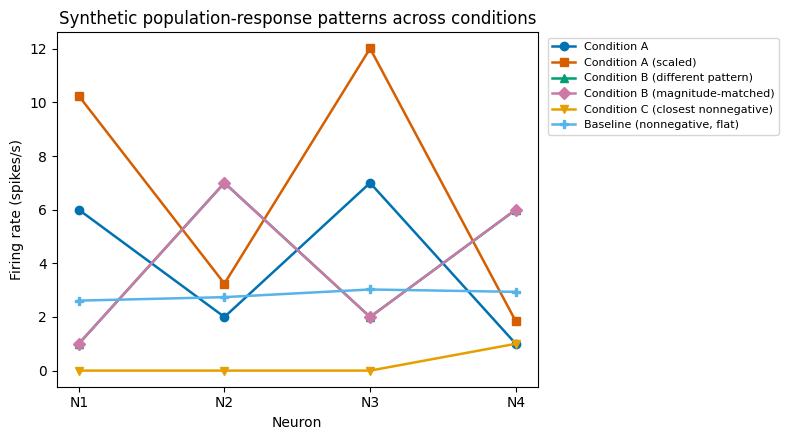

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x_pos = np.arange(len(neuron_labels))
for i, (name, vec) in enumerate(conditions.items()):
    ax.plot(x_pos, vec, marker=MARKERS[i % len(MARKERS)], color=PALETTE[i % len(PALETTE)],
            label=name, linewidth=1.8)
ax.set_xticks(x_pos); ax.set_xticklabels(neuron_labels)
ax.set_xlabel('Neuron'); ax.set_ylabel('Firing rate (spikes/s)')
ax.set_title('Synthetic population-response patterns across conditions')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.0))
no_grid(ax)
plt.tight_layout()
plt.show()

In [17]:
# INTERACTIVE VERSION -- hoverable response-pattern comparison
fig_patterns = go.Figure()
for i, (name, vec) in enumerate(conditions.items()):
    fig_patterns.add_trace(go.Scatter(
        x=neuron_labels, y=vec, mode='lines+markers', name=name,
        marker=dict(symbol=PLOTLY_MARKERS[i % len(PLOTLY_MARKERS)], size=9),
        line=dict(color=PALETTE[i % len(PALETTE)]),
        hovertemplate=f'{name}<br>%{{x}}: %{{y:.2f}} spikes/s<extra></extra>',
    ))
fig_patterns.update_layout(
    title='Population-response patterns (hover to inspect each condition)',
    xaxis_title='Neuron', yaxis_title='Firing rate (spikes/s)',
    template='plotly_white', width=760, height=460,
    legend=dict(x=1.02, y=1.0),
)
style_plotly_axes(fig_patterns)
fig_patterns.show(config=PLOTLY_CONFIG)

### Representational similarity matrix

A **representational similarity matrix (RSA matrix)** collects the pairwise cosine
similarity between every pair of condition vectors into one grid — a compact way to see
which conditions the population treats as "similar" in direction.

In [18]:
condition_names = list(conditions.keys())
condition_matrix = np.stack(list(conditions.values()))
n_cond = len(condition_names)

similarity_matrix = np.zeros((n_cond, n_cond))
for i in range(n_cond):
    for j in range(n_cond):
        similarity_matrix[i, j] = cosine_similarity(condition_matrix[i], condition_matrix[j])

print("Cosine similarity matrix:")
print(np.round(similarity_matrix, 2))

Cosine similarity matrix:
[[1.   1.   0.44 0.44 0.11 0.84]
 [1.   1.   0.44 0.44 0.11 0.84]
 [0.44 0.44 1.   1.   0.63 0.85]
 [0.44 0.44 1.   1.   0.63 0.85]
 [0.11 0.11 0.63 0.63 1.   0.52]
 [0.84 0.84 0.85 0.85 0.52 1.  ]]


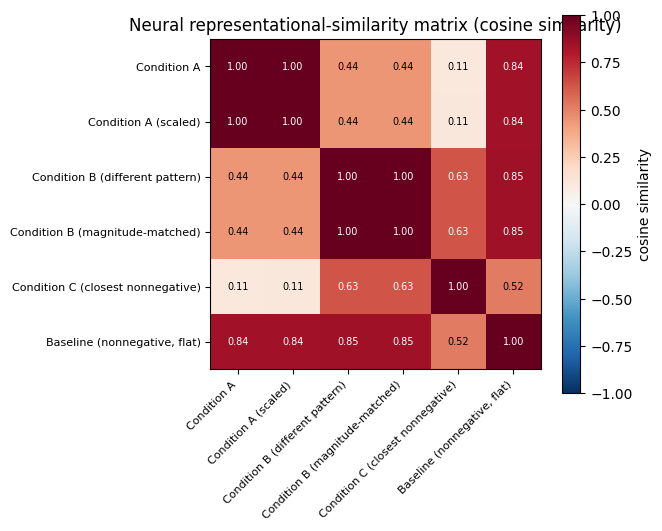

In [19]:
# Static similarity-matrix heatmap.
fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(similarity_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(n_cond)); ax.set_xticklabels(condition_names, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(n_cond)); ax.set_yticklabels(condition_names, fontsize=8)
for i in range(n_cond):
    for j in range(n_cond):
        ax.text(j, i, f'{similarity_matrix[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(similarity_matrix[i, j]) > 0.6 else 'black')
ax.set_title('Neural representational-similarity matrix (cosine similarity)')
plt.colorbar(im, ax=ax, label='cosine similarity')
no_grid(ax)
plt.tight_layout()
plt.show()

In [20]:
# INTERACTIVE VERSION -- Plotly similarity heatmap with exact values on hover.
fig_heatmap = go.Figure(data=go.Heatmap(
    z=similarity_matrix, x=condition_names, y=condition_names,
    colorscale='RdBu', zmid=0, zmin=-1, zmax=1,
    text=np.round(similarity_matrix, 2), texttemplate='%{text}',
    hovertemplate='%{y} vs %{x}<br>cosine similarity = %{z:.3f}<extra></extra>',
    colorbar=dict(title='cos_sim'),
))
fig_heatmap.update_layout(
    title='Interactive neural representational-similarity matrix',
    template='plotly_white', width=680, height=620,
    xaxis=dict(tickangle=45),
)
# A heatmap's cell boundaries are informative structure, not a background grid -- kept as is.
fig_heatmap.update_xaxes(showgrid=False)
fig_heatmap.update_yaxes(showgrid=False, autorange='reversed')
fig_heatmap.show(config=PLOTLY_CONFIG)

# **Part 7: Projection**

Given a vector $\mathbf{u}$ and a chosen direction $\mathbf{v}$, **projection** answers:
*how much of $\mathbf{u}$ lies along $\mathbf{v}$?*

**Scalar projection** (a single number, the signed coordinate along $\mathbf{v}$):

$$
\operatorname{comp}_{\mathbf{v}}(\mathbf{u}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{v}\rVert}.
$$

**Vector projection** (a vector, lying exactly along $\mathbf{v}$):

$$
\operatorname{proj}_{\mathbf{v}}(\mathbf{u}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\,\mathbf{v}.
$$

**Residual** (what is left over, orthogonal to $\mathbf{v}$ by construction):

$$
\mathbf{u}_\perp = \mathbf{u} - \operatorname{proj}_{\mathbf{v}}(\mathbf{u}).
$$

**Scalar vs. vector projection.** $\operatorname{comp}_{\mathbf{v}}(\mathbf{u})$ is a number
with the units of $\mathbf{u}$; $\operatorname{proj}_{\mathbf{v}}(\mathbf{u})$ is a vector
pointing along $\mathbf{v}$ with that length. When $\mathbf{v}$ is already a **unit**
vector $\hat{\mathbf{v}}$, the scalar-projection formula simplifies to
$\mathbf{u}\cdot\hat{\mathbf{v}}$ (no division needed, since $\lVert\hat{\mathbf{v}}\rVert = 1$)
— but for a non-unit $\mathbf{v}$, skipping the division by $\lVert\mathbf{v}\rVert$ (or by
$\mathbf{v}\cdot\mathbf{v}$ in the vector-projection formula) is one of the most common
implementation mistakes.

In [21]:
def scalar_projection(u, v, eps=1e-12):
    norm_v = np.linalg.norm(v)
    if norm_v < eps:
        raise ValueError("Cannot project onto a zero vector (no direction is defined).")
    return (u @ v) / norm_v

def vector_projection(u, v, eps=1e-12):
    denom = v @ v
    if denom < eps:
        raise ValueError("Cannot project onto a zero vector (no direction is defined).")
    return ((u @ v) / denom) * v

def residual_component(u, v):
    return u - vector_projection(u, v)

u_proj_demo = np.array([4.0, 3.0])
v_proj_demo = np.array([2.0, 0.0])   # projecting onto the coordinate-1 axis, for a simple check

comp = scalar_projection(u_proj_demo, v_proj_demo)
proj_vec = vector_projection(u_proj_demo, v_proj_demo)
resid = residual_component(u_proj_demo, v_proj_demo)

print("Scalar projection comp_v(u):", round(comp, 3))
print("Vector projection proj_v(u):", np.round(proj_vec, 3))
print("Residual u_perp            :", np.round(resid, 3))

# Verify the residual really is orthogonal to v.
print("\nResidual . v =", round(resid @ v_proj_demo, 8), " (should be ~0)")
print("u == proj + residual?", np.allclose(u_proj_demo, proj_vec + resid))

Scalar projection comp_v(u): 4.0
Vector projection proj_v(u): [4. 0.]
Residual u_perp            : [0. 3.]

Residual . v = 0.0  (should be ~0)
u == proj + residual? True


### Static projection diagram

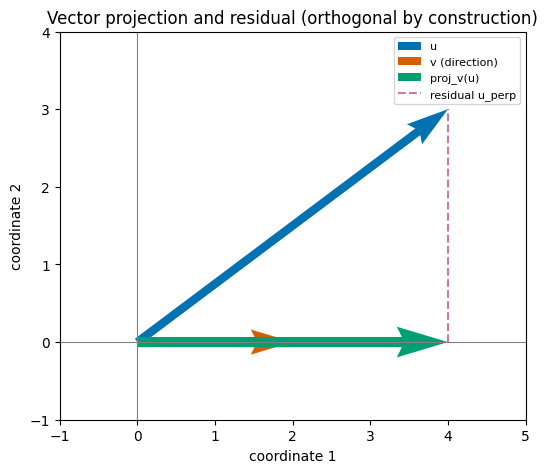

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.quiver(0, 0, u_proj_demo[0], u_proj_demo[1], angles='xy', scale_units='xy', scale=1,
          color=PALETTE[0], width=0.018, label='u')
ax.quiver(0, 0, v_proj_demo[0], v_proj_demo[1], angles='xy', scale_units='xy', scale=1,
          color=PALETTE[1], width=0.018, label='v (direction)')
ax.quiver(0, 0, proj_vec[0], proj_vec[1], angles='xy', scale_units='xy', scale=1,
          color=PALETTE[2], width=0.022, label='proj_v(u)')
ax.plot([proj_vec[0], u_proj_demo[0]], [proj_vec[1], u_proj_demo[1]], ls='--',
        color=PALETTE[3], label='residual u_perp')
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
ax.set_xlim(-1, 5); ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.set_xlabel('coordinate 1'); ax.set_ylabel('coordinate 2')
ax.set_title('Vector projection and residual (orthogonal by construction)')
ax.legend(fontsize=8)
no_grid(ax)
plt.tight_layout()
plt.show()

### Interactive projection decomposition with a rotating direction

Rotate the projection direction $\mathbf{v}$ and watch $\operatorname{proj}_{\mathbf{v}}(\mathbf{u})$
and the residual update together. The dashed segment (residual) should always meet
$\mathbf{v}$'s line at a right angle.

In [23]:
# INTERACTIVE ANIMATION -- rotating projection direction.
u_fixed_proj = np.array([4.0, 2.5])
proj_angles_deg = np.arange(0, 181, 4)   # a direction and its opposite describe the same line
proj_angles_rad = np.radians(proj_angles_deg)
directions = np.stack([np.cos(proj_angles_rad), np.sin(proj_angles_rad)], axis=1)

proj_vectors = np.array([vector_projection(u_fixed_proj, d) for d in directions])
residuals = u_fixed_proj - proj_vectors
comp_values = np.array([scalar_projection(u_fixed_proj, d) for d in directions])

axis_lim_proj = 5.0

def proj_frame_traces(k):
    d = directions[k] * axis_lim_proj
    p = proj_vectors[k]
    return [
        go.Scatter(x=[-d[0], d[0]], y=[-d[1], d[1]], mode='lines',
                   line=dict(color=PALETTE[1], width=2, dash='dot'), name='direction line'),
        go.Scatter(x=[0, p[0]], y=[0, p[1]], mode='lines+markers',
                   line=dict(color=PALETTE[2], width=5),
                   marker=dict(size=[1, 11], symbol=['circle', 'triangle-right']),
                   name='proj_v(u)'),
        go.Scatter(x=[p[0], u_fixed_proj[0]], y=[p[1], u_fixed_proj[1]], mode='lines',
                   line=dict(color=PALETTE[3], width=3, dash='dash'), name='residual'),
    ]

fig_proj = go.Figure(
    data=[
        go.Scatter(x=[0, u_fixed_proj[0]], y=[0, u_fixed_proj[1]], mode='lines+markers',
                   line=dict(color=PALETTE[0], width=5),
                   marker=dict(size=[1, 12], symbol=['circle', 'triangle-right']), name='u (fixed)'),
    ] + proj_frame_traces(0),
)
frames = []
for k in range(len(proj_angles_deg)):
    d = directions[k] * axis_lim_proj
    p = proj_vectors[k]
    frames.append(go.Frame(
        name=str(k),
        data=[
            go.Scatter(x=[-d[0], d[0]], y=[-d[1], d[1]]),
            go.Scatter(x=[0, p[0]], y=[0, p[1]]),
            go.Scatter(x=[p[0], u_fixed_proj[0]], y=[p[1], u_fixed_proj[1]]),
        ],
        traces=[1, 2, 3],
    ))
fig_proj.frames = frames
fig_proj.update_xaxes(range=[-axis_lim_proj, axis_lim_proj], title_text='coordinate 1',
                       scaleanchor='y', scaleratio=1)
fig_proj.update_yaxes(range=[-axis_lim_proj, axis_lim_proj], title_text='coordinate 2')
style_plotly_axes(fig_proj)
fig_proj.update_layout(
    title='Projection direction rotating: proj_v(u) and residual update together',
    template='plotly_white', width=680, height=620,
    updatemenus=[play_pause_buttons(y=-0.1)],
    sliders=[frame_slider([f'{a} deg' for a in proj_angles_deg], prefix='direction angle = ')],
)
fig_proj.show(config=PLOTLY_CONFIG)

print("Press Play or drag the slider. Verify: residual . direction stays close to 0 at every frame.")
print("Max |residual . direction| across all frames:",
      np.max(np.abs(np.sum(residuals * directions, axis=1))))

Press Play or drag the slider. Verify: residual . direction stays close to 0 at every frame.
Max |residual . direction| across all frames: 6.661338147750939e-16


**Visual proof of orthogonality.** The maximum value printed above should be extremely
small (floating-point noise, not exactly zero — the same `np.isclose` lesson from Part 4
applies here). This is not a coincidence: the projection formula is *defined* so that the
residual is orthogonal to the projection direction, for any $\mathbf{u}$ and any nonzero
$\mathbf{v}$.

**A common mistake avoided.** If $\mathbf{v}$ is not a unit vector, forgetting to divide by
$\mathbf{v}\cdot\mathbf{v}$ (using just $\mathbf{u}\cdot\mathbf{v}$ instead) silently
produces a vector that is not actually on the line through $\mathbf{v}$. The interactive
figure above uses unit-length directions throughout to keep the two formulas from being
confused; Exercise 4 asks you to repeat the calculation with a non-unit $\mathbf{v}$.

# **Part 8: Preferred direction and neural tuning**

The weight vector $\mathbf{w}$ is not just "a list of
numbers," it is a **direction** in input space — often called the neuron's **preferred
direction**. If the stimulus vector $\mathbf{x}$ has a fixed magnitude but a varying
direction (angle $\phi$), the dot-product response

$$
z(\phi) = \mathbf{w}\cdot\mathbf{x}(\phi) = \lVert\mathbf{w}\rVert\,\lVert\mathbf{x}\rVert\cos(\phi - \phi_w)
$$

is exactly the rotation curve from Part 3, now read as a **tuning curve**: response is
largest when the stimulus aligns with the preferred direction $\phi_w$, zero when
orthogonal to it, and most negative when opposite to it.

In [24]:
preferred_direction_deg = 40.0
preferred_direction_rad = np.radians(preferred_direction_deg)
w_preferred = np.array([np.cos(preferred_direction_rad), np.sin(preferred_direction_rad)])  # unit vector
stimulus_magnitude = 3.0

stimulus_angles_deg = np.arange(0, 361, 4)
stimulus_angles_rad = np.radians(stimulus_angles_deg)
stimulus_vectors = stimulus_magnitude * np.stack(
    [np.cos(stimulus_angles_rad), np.sin(stimulus_angles_rad)], axis=1)
tuning_response = stimulus_vectors @ w_preferred

# The response is zero exactly 90 degrees away from the preferred direction,
# on either side -- compute both stimulus angles analytically rather than
# just reading off the closest sampled grid point.
zero_crossings = np.mod([preferred_direction_deg + 90.0, preferred_direction_deg - 90.0], 360.0)

print("Preferred direction (unit vector):", np.round(w_preferred, 3), f"  ({preferred_direction_deg} deg)")
print("Max response at stimulus angle   :", stimulus_angles_deg[np.argmax(tuning_response)], "deg")
print("Response is exactly zero at stimulus angles:",
      f"{zero_crossings[0]:.0f} deg and {zero_crossings[1]:.0f} deg",
      f"(90 deg on either side of the {preferred_direction_deg:.0f} deg preferred direction)")

Preferred direction (unit vector): [0.766 0.643]   (40.0 deg)
Max response at stimulus angle   : 40 deg
Response is exactly zero at stimulus angles: 130 deg and 310 deg (90 deg on either side of the 40 deg preferred direction)


### Static tuning-curve figure

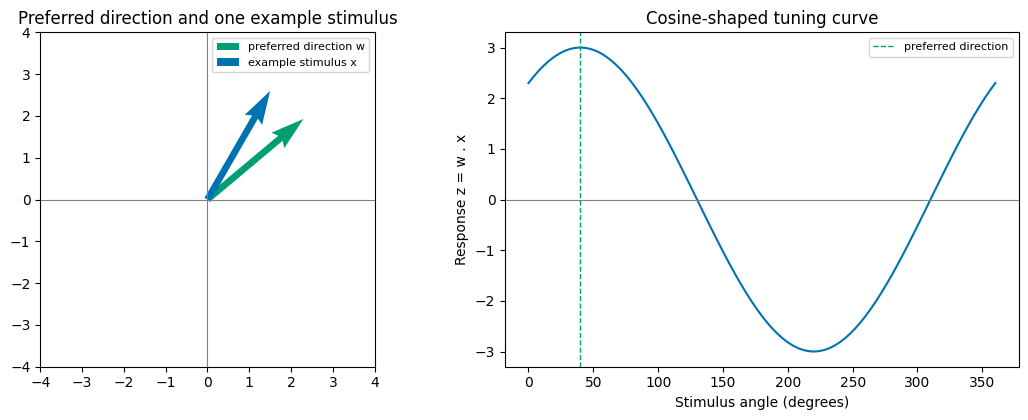

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
ax.quiver(0, 0, w_preferred[0] * stimulus_magnitude, w_preferred[1] * stimulus_magnitude,
          angles='xy', scale_units='xy', scale=1, color=PALETTE[2], width=0.02,
          label='preferred direction w')
example_angle_idx = 15
ex_stim = stimulus_vectors[example_angle_idx]
ax.quiver(0, 0, ex_stim[0], ex_stim[1], angles='xy', scale_units='xy', scale=1,
          color=PALETTE[0], width=0.02, label='example stimulus x')
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect('equal')
ax.set_title('Preferred direction and one example stimulus')
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(stimulus_angles_deg, tuning_response, color=PALETTE[0])
ax.axhline(0, color='grey', lw=0.8)
ax.axvline(preferred_direction_deg, color=PALETTE[2], ls='--', lw=1, label='preferred direction')
ax.set_xlabel('Stimulus angle (degrees)'); ax.set_ylabel('Response z = w . x')
ax.set_title('Cosine-shaped tuning curve')
ax.legend(fontsize=8)
no_grid(axes)
plt.tight_layout()
plt.show()

### Linked interactive: rotating stimulus and its position on the tuning curve

Rotate the stimulus and watch its marker move along the tuning curve on the right. A
slider also lets you change the preferred direction itself.

In [26]:
# INTERACTIVE ANIMATION -- stimulus rotation linked to the tuning curve.
fig_tuning = make_subplots(rows=1, cols=2, subplot_titles=('Stimulus and preferred direction', 'Tuning curve'))

fig_tuning.add_trace(go.Scatter(
    x=[0, w_preferred[0] * stimulus_magnitude], y=[0, w_preferred[1] * stimulus_magnitude],
    mode='lines+markers', line=dict(color=PALETTE[2], width=5),
    marker=dict(size=[1, 12], symbol=['circle', 'triangle-right']), name='preferred direction w'),
    row=1, col=1)
fig_tuning.add_trace(go.Scatter(
    x=[0, stimulus_vectors[0, 0]], y=[0, stimulus_vectors[0, 1]], mode='lines+markers',
    line=dict(color=PALETTE[0], width=5),
    marker=dict(size=[1, 12], symbol=['circle', 'triangle-right']), name='stimulus x(phi)'),
    row=1, col=1)
fig_tuning.add_trace(go.Scatter(x=stimulus_angles_deg, y=tuning_response, mode='lines',
                                 line=dict(color='lightgrey', width=2), hoverinfo='skip',
                                 name='tuning curve'), row=1, col=2)
fig_tuning.add_trace(go.Scatter(x=[stimulus_angles_deg[0]], y=[tuning_response[0]], mode='markers',
                                 marker=dict(color=PALETTE[0], size=12), name='current response'),
                      row=1, col=2)
fig_tuning.add_vline(x=preferred_direction_deg, line_dash='dash', line_color=PALETTE[2], row=1, col=2)
fig_tuning.add_hline(y=0, line_width=1, line_color='grey', row=1, col=2)

frames = []
for k in range(len(stimulus_angles_deg)):
    s = stimulus_vectors[k]
    frames.append(go.Frame(
        name=str(k),
        data=[go.Scatter(x=[0, s[0]], y=[0, s[1]]),
              go.Scatter(x=[stimulus_angles_deg[k]], y=[tuning_response[k]])],
        traces=[1, 3],
    ))
fig_tuning.frames = frames

fig_tuning.update_xaxes(range=[-4, 4], row=1, col=1, scaleanchor='y', scaleratio=1, title_text='coordinate 1')
fig_tuning.update_yaxes(range=[-4, 4], row=1, col=1, title_text='coordinate 2')
fig_tuning.update_xaxes(range=[0, 360], row=1, col=2, title_text='stimulus angle (degrees)')
fig_tuning.update_yaxes(range=list(padded_limits(tuning_response)), row=1, col=2, title_text='response z')
style_plotly_axes(fig_tuning)
fig_tuning.update_layout(
    title='Rotating stimulus linked to its position on the tuning curve',
    template='plotly_white', width=980, height=460,
    updatemenus=[play_pause_buttons(x=0.0, y=-0.18)],
    sliders=[frame_slider([f'{a} deg' for a in stimulus_angles_deg], prefix='stimulus angle = ')],
)
fig_tuning.show(config=PLOTLY_CONFIG)

print("Press Play or drag the slider. The marker on the right tracks the current stimulus angle.")

Press Play or drag the slider. The marker on the right tracks the current stimulus angle.


### Limitation

Real neuronal tuning curves are frequently *not* a perfect cosine: they commonly show a
nonzero baseline firing rate, rectification (no firing below some threshold, rather than
literally negative firing), response saturation at high stimulus drive, and trial-to-trial
noise. The cosine-tuning model here isolates the **linear, dot-product part** of tuning; it
is a starting point for describing real tuning curves, not a complete description of one.